In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

En lugar del cuadro de prelaciones habitual, el responsable del proyecto ha anotado para cada actividad cuáles pueden empezar *inmediatamente después* de ella (sus sucesoras inmediatas) y su duración en semanas.

In [4]:
pregunta_1 = "1. Construya el cuadro de prelaciones (predecesoras inmediatas) a partir del de sucesoras. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen en cada uno de los dos cuadros?  "
pregunta_2 = "2. Dibuje el grafo Roy y el grafo PERT. ¿Cuántas ficticias necesita el PERT?  "
pregunta_3 = "3. Calcule el calendario y el camino crítico.  "
pregunta_4 = "4. Compruebe que el cuadro de sucesoras y el de predecesoras contienen la misma información: reconstruya el de sucesoras a partir del de predecesoras.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya el cuadro de prelaciones (predecesoras inmediatas) a partir del de sucesoras. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen en cada uno de los dos cuadros?  

2. Dibuje el grafo Roy y el grafo PERT. ¿Cuántas ficticias necesita el PERT?  

3. Calcule el calendario y el camino crítico.  

4. Compruebe que el cuadro de sucesoras y el de predecesoras contienen la misma información: reconstruya el de sucesoras a partir del de predecesoras.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (sucesoras inmediatas)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, successor, duration
    ('A'     , 'C'      , 5       ),
    ('B'     , 'C,F'    , 2       ),
    ('C'     , 'D'      , 1       ),
    ('D'     , 'E'      , 4       ),
    ('E'     , 'G'      , 8       ),
    ('F'     , 'H'      , 1       ),
    ('G'     , 'H'      , 8       ),
    ('H'     , '---'    , 2       ),
], columns=['activity', 'successor', 'duration']).set_index('activity')
datos_enunciado

,successor,duration
activity,,
A,C,5
B,"C,F",2
C,D,1
D,E,4
E,G,8
F,H,1
G,H,8
H,---,2


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató


# Resolución

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Construya el cuadro de prelaciones (predecesoras inmediatas) a partir del de sucesoras. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen en cada uno de los dos cuadros?  

Si $B$ aparece entre las sucesoras de $A$, entonces $A$ es predecesora de $B$. Se recorre el cuadro fila a fila anotando cada actividad como predecesora de las que figuran en su casilla. Las iniciales son las que no aparecen en ninguna casilla de sucesoras (ninguna las precede); las finales, las que tienen `---` en sucesoras.

In [8]:
predecesoras = {a: [] for a in datos_enunciado.index}
for a, s in datos_enunciado['successor'].items():
    if s != '---':
        for b in s.split(','):
            predecesoras[b.strip()].append(a)
datos_proyecto = pd.DataFrame({'predecessor': {a: (','.join(sorted(ps)) if ps else '---') for a, ps in predecesoras.items()},
                              'duration': datos_enunciado['duration']})
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor,duration
activity,,
A,---,5
B,---,2
C,"A,B",1
D,C,4
E,D,8
F,B,1
G,E,8
H,"F,G",2


In [9]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
print('Iniciales (sin predecesoras):', ', '.join(sorted(prelaciones.start_activities)))
print('Finales (sin sucesoras):     ', ', '.join(sorted(prelaciones.end_activities)))

Iniciales (sin predecesoras): A, B
Finales (sin sucesoras):      H


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Dibuje el grafo Roy y el grafo PERT. ¿Cuántas ficticias necesita el PERT?  

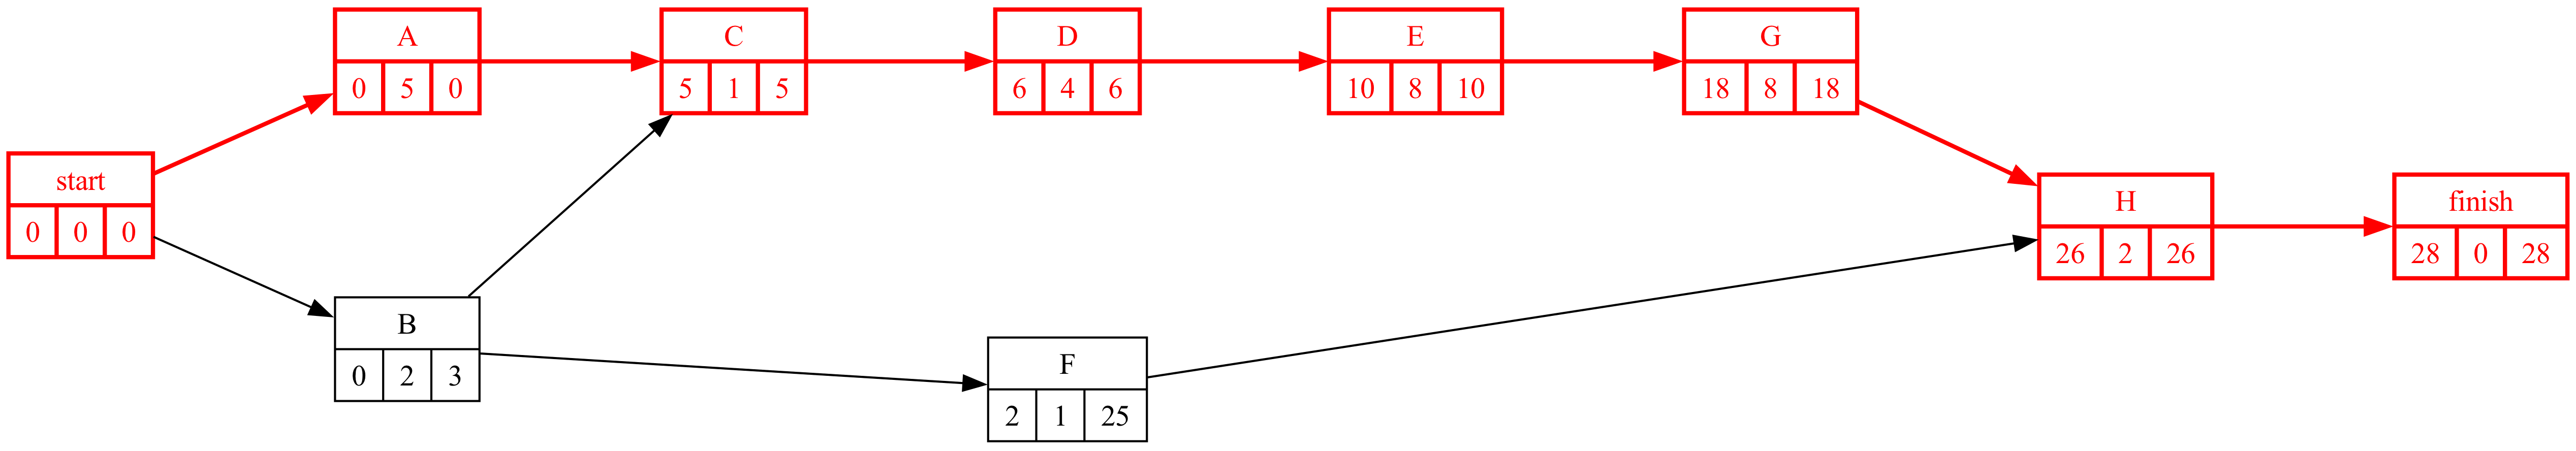

In [11]:
#| fig-cap: "Grafo Roy"
#| label: fig-roy
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

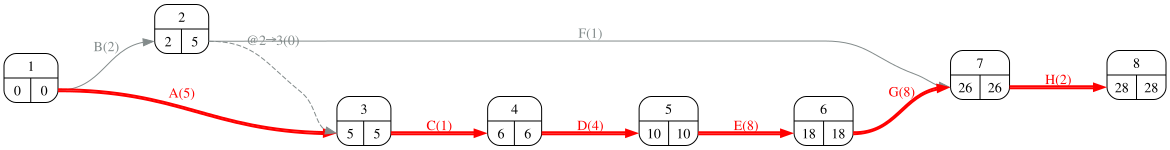

In [12]:
#| fig-cap: "Grafo PERT"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Cálculo de los tiempos tempranos y tardíos de los sucesos paso a paso (avance con los botones):

In [ ]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

In [13]:
Markdown(f'El PERT necesita {len(proyecto.dummies)} actividad(es) ficticia(s); el Roy, ninguna.')

El PERT necesita 1 actividad(es) ficticia(s); el Roy, ninguna.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Calcule el calendario y el camino crítico.  

In [15]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,5,5,0,0,0,5
B,0,3,2,5,0,0,3,2
C,5,5,6,6,0,0,0,1
D,6,6,10,10,0,0,0,4
E,10,10,18,18,0,0,0,8
F,2,25,3,26,23,20,23,1
G,18,18,26,26,0,0,0,8
H,26,26,28,28,0,0,0,2


In [16]:
#| tbl-cap: "Cálculo paso a paso de las fechas"
#| label: tbl-fechasPaso
detalle_holguras(calendario, prelaciones)[['ES = máx EF pred.', 'EF = ES + d', 'LF = mín LS suc.', 'LS = LF − d']]

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d
actividad,,,,
A,inicial → 0,0 + 5 = 5,mín(C: 5) = 5,5 − 5 = 0
B,inicial → 0,0 + 2 = 2,"mín(C: 5, F: 25) = 5",5 − 2 = 3
C,"máx(A: 5, B: 2) = 5",5 + 1 = 6,mín(D: 6) = 6,6 − 1 = 5
D,máx(C: 6) = 6,6 + 4 = 10,mín(E: 10) = 10,10 − 4 = 6
E,máx(D: 10) = 10,10 + 8 = 18,mín(G: 18) = 18,18 − 8 = 10
F,máx(B: 2) = 2,2 + 1 = 3,mín(H: 26) = 26,26 − 1 = 25
G,máx(E: 18) = 18,18 + 8 = 26,mín(H: 26) = 26,26 − 8 = 18
H,"máx(F: 3, G: 26) = 26",26 + 2 = 28,final → 28,28 − 2 = 26


In [17]:
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'La duración del proyecto es {duracion_proyecto} semanas.')

- Route_1 :	A, C, D, E, G, H <br> 

La duración del proyecto es 28 semanas.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Compruebe que el cuadro de sucesoras y el de predecesoras contienen la misma información: reconstruya el de sucesoras a partir del de predecesoras.  

In [19]:
sucesoras = {a: sorted(b for b, ps in prelaciones.immediate_predecessor.items() if a in ps) for a in datos_proyecto.index}
reconstruido = pd.Series({a: (','.join(s) if s else '---') for a, s in sucesoras.items()}, name='successor')
coincide = (reconstruido == datos_enunciado['successor'].map(lambda s: ','.join(sorted(s.split(','))) if s != '---' else s)).all()
display(pd.concat({'enunciado': datos_enunciado['successor'], 'reconstruido': reconstruido}, axis=1))
Markdown(f'Los dos cuadros coinciden: {coincide}. Son la misma relación leída en los dos sentidos.')

,enunciado,reconstruido
A,C,C
B,"C,F","C,F"
C,D,D
D,E,E
E,G,G
F,H,H
G,H,H
H,---,---


Los dos cuadros coinciden: True. Son la misma relación leída en los dos sentidos.